# NeuroScan — classifying brain tumours on MRI

This notebook runs the whole study on the slices stored in `data/`, using the `neuroscan`
package: it loads the dataset, shows what the images look like, extracts features, trains
five classifiers and measures them the way a medical result has to be measured.

| Step | What it does |
|---|---|
| 1 | Load the slices and check that no patient can leak between folds |
| 2 | Look at the images and at the signal the features capture |
| 3 | Extract features and train the classifiers |
| 4 | Report sensitivity, specificity and F1 per class |
| 5 | Show what a slice-wise split would have reported instead |

To rebuild the images from the original archives, run `scripts/01_prepare_dataset.py`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd

from neuroscan import CLASS_NAMES
from neuroscan.dataset import (class_distribution, cross_validation_splits, leaky_split,
                               load_index, to_frame)
from neuroscan.evaluation import majority_class_baseline
from neuroscan.features import build_matrix, histogram_features, read_grayscale
from neuroscan.models import build_models, evaluate
from neuroscan.texture import texture_features

DATA = Path.cwd().parent / "data"
pd.set_option("display.width", 120)

## 1. The slices

Each row is one MRI slice. Several slices come from the same patient, so the `patient_id`
column is what makes an honest split possible, and `fold` is the official 5-fold
assignment published with the dataset.

In [2]:
slices = load_index(DATA)
frame = to_frame(slices)

print(f"{len(slices)} slices from {frame.patient_id.nunique()} patients")
print(f"majority-class baseline: {100 * majority_class_baseline(frame.label):.1f} %")
class_distribution(slices)

449 slices from 75 patients
majority-class baseline: 33.4 %


,label,class,slices,patients
0,1,meningioma,149,25
1,2,glioma,150,25
2,3,pituitary,150,25


The decisive check: a patient must never appear in two folds. If this ever printed a
number other than zero, every result below would be worthless.

In [3]:
spanning = frame.groupby("patient_id")["fold"].nunique()
print("patients present in more than one fold:", int((spanning > 1).sum()))

for fold, train, test in cross_validation_splits(slices):
    shared = {i.patient_id for i in train} & {i.patient_id for i in test}
    print(f"fold {fold}: {len(train):>3} train, {len(test):>3} test, shared patients: {len(shared)}")

patients present in more than one fold: 0
fold 1: 354 train,  95 test, shared patients: 0
fold 2: 371 train,  78 test, shared patients: 0
fold 3: 359 train,  90 test, shared patients: 0
fold 4: 365 train,  84 test, shared patients: 0
fold 5: 347 train, 102 test, shared patients: 0


## 2. What the images look like

The three tumour types sit in different places and have different borders: a meningioma is
attached to the membranes around the brain, a glioma grows inside the brain tissue with a
diffuse edge, and a pituitary tumour sits at the base of the skull.

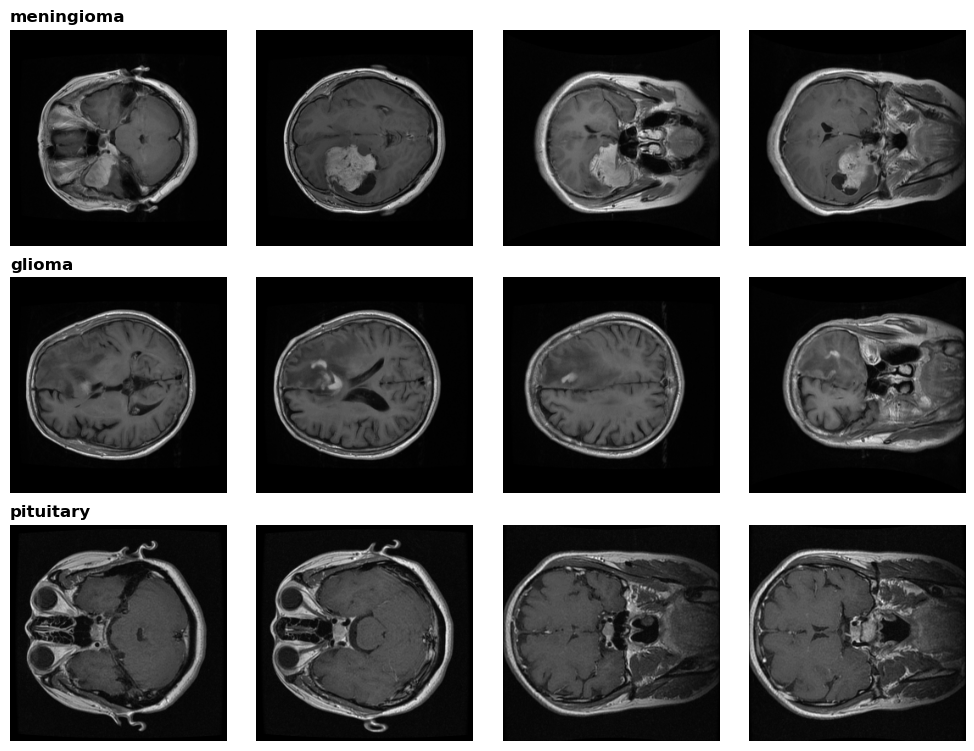

In [4]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(3, 4, figsize=(10, 7.6))
for row, (label, name) in enumerate(CLASS_NAMES.items()):
    chosen = [s for s in slices if s.label == label][:4]
    for column, item in enumerate(chosen):
        axes[row, column].imshow(read_grayscale(item.path), cmap="gray")
        axes[row, column].axis("off")
    axes[row, 0].set_title(name, loc="left", fontweight="bold")
figure.tight_layout()

The first description the project used is the histogram of grey levels of each region of a
4 × 4 grid. The averaged histogram of the central region already separates the classes a
little, which is why even the simplest rule works better than chance.

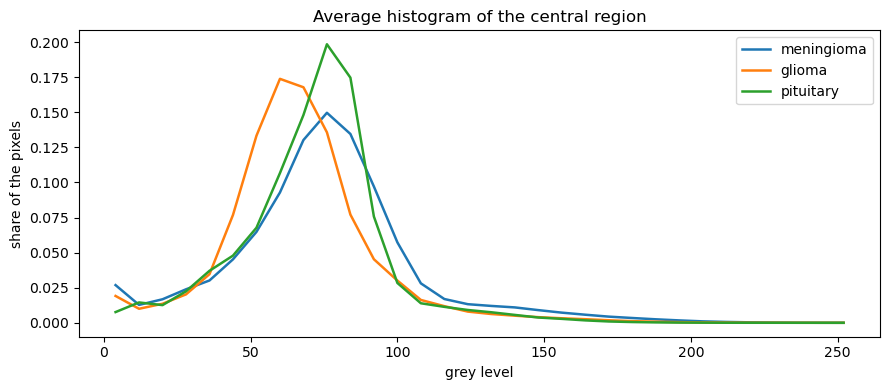

In [5]:
from neuroscan.features import DEFAULT_BINS, region_histogram, split_into_regions

figure, axes = plt.subplots(figsize=(9, 4))
for label, name in CLASS_NAMES.items():
    group = [s for s in slices if s.label == label]
    middles = [region_histogram(split_into_regions(read_grayscale(s.path))[5], DEFAULT_BINS)
               for s in group]
    axes.plot((np.arange(DEFAULT_BINS) + 0.5) * 256 / DEFAULT_BINS,
              np.mean(middles, axis=0), label=name, linewidth=1.8)
axes.set_xlabel("grey level"); axes.set_ylabel("share of the pixels")
axes.set_title("Average histogram of the central region"); axes.legend()
figure.tight_layout()

## 3. Training and measuring

The same five classifiers are run on two descriptions of the image: the regional
histograms the project started from, and texture descriptors that look at how the pixels
are arranged rather than only how bright they are.

In [6]:
from functools import partial

def cached(builder):
    store = {}
    def inner(items):
        key = tuple(i.slice_id for i in items)
        if key not in store:
            store[key] = builder(items)
        return store[key]
    return inner

feature_sets = {
    "Histograms": cached(partial(build_matrix, extractor=histogram_features)),
    "Texture (LBP + HOG)": cached(partial(build_matrix, extractor=texture_features)),
}

rows, results = [], {}
for feature_name, features_of in feature_sets.items():
    for model_name, model in build_models().items():
        result = evaluate(model, cross_validation_splits(slices), features_of,
                          f"{model_name} + {feature_name}")
        results[result.name] = result
        summary = result.summary()
        summary.update(features=feature_name, classifier=model_name)
        rows.append(summary)

table = pd.DataFrame(rows).sort_values("balanced_accuracy", ascending=False)
table[["features", "classifier", "balanced_accuracy", "balanced_accuracy_std",
       "macro_f1", "auc_ovr"]].round(3)

,features,classifier,balanced_accuracy,balanced_accuracy_std,macro_f1,auc_ovr
9,Texture (LBP + HOG),Random forest,0.842,0.010,0.842,0.935
7,Texture (LBP + HOG),SVM (RBF),0.813,0.029,0.813,0.921
8,Texture (LBP + HOG),Logistic regression,0.788,0.023,0.788,0.912
2,Histograms,SVM (RBF),0.777,0.047,0.774,0.899
4,Histograms,Random forest,0.755,0.010,0.752,0.891
6,Texture (LBP + HOG),k-NN (k=5),0.730,0.045,0.725,0.864
1,Histograms,k-NN (k=5),0.712,0.024,0.707,0.874
3,Histograms,Logistic regression,0.703,0.055,0.701,0.866
0,Histograms,Nearest class histogram,0.641,0.024,0.640,0.822
5,Texture (LBP + HOG),Nearest class histogram,0.630,0.050,0.622,0.823


## 4. What the best model actually does

Accuracy is not enough: with three classes, a model can look acceptable while missing one
tumour type almost entirely. Sensitivity says how many cases of a class were found,
specificity how rarely the class is raised wrongly.

In [7]:
best_name = table.iloc[0]["model"]
best = results[best_name]
print(best_name, "\n")
pd.DataFrame(best.per_class()).round(3)

Random forest + Texture (LBP + HOG) 



,class,support,sensitivity,specificity,precision,f1
0,meningioma,149,0.852,0.867,0.760,0.804
1,glioma,150,0.747,0.983,0.957,0.839
2,pituitary,150,0.927,0.913,0.842,0.883


In [8]:
from neuroscan.plotting import CLASS_COLOURS

matrix = best.confusion()
names = [CLASS_NAMES[c] for c in sorted(CLASS_NAMES)]
percent = 100 * matrix / matrix.sum(axis=1, keepdims=True)

figure, axes = plt.subplots(figsize=(5.4, 4.8))
axes.imshow(percent, cmap="Blues", vmin=0, vmax=100)
for i in range(3):
    for j in range(3):
        axes.text(j, i, f"{matrix[i, j]}\n{percent[i, j]:.0f} %", ha="center", va="center",
                  color="white" if percent[i, j] > 55 else "#22313F")
axes.set_xticks(range(3), names, rotation=20, ha="right"); axes.set_yticks(range(3), names)
axes.set_xlabel("predicted"); axes.set_ylabel("true"); axes.set_title("Confusion matrix")
figure.tight_layout()

## 5. The mistake worth showing

Splitting the slices at random instead of the patients puts other slices of the same
patient in the test set. Those slices are near-copies of the training ones, so the model
is partly being tested on what it has already seen.

In [9]:
train, test = leaky_split(slices, test_size=0.3, seed=0)
shared = {i.patient_id for i in train} & {i.patient_id for i in test}
print(f"a random split shares {len(shared)} of {frame.patient_id.nunique()} patients "
      "between training and test")

a random split shares 68 of 75 patients between training and test


In [10]:
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

features_of = feature_sets["Texture (LBP + HOG)"]
comparison = []
for model_name, model in build_models().items():
    honest = results[f"{model_name} + Texture (LBP + HOG)"].summary()["balanced_accuracy"]
    scores = []
    for seed in range(5):
        tr, te = leaky_split(slices, test_size=0.3, seed=seed)
        X_tr, y_tr = features_of(tr)
        X_te, y_te = features_of(te)
        scores.append(balanced_accuracy_score(y_te, clone(model).fit(X_tr, y_tr).predict(X_te)))
    comparison.append({"classifier": model_name,
                       "patient-wise": round(100 * honest, 1),
                       "slice-wise": round(100 * np.mean(scores), 1),
                       "inflation": round(100 * (np.mean(scores) - honest), 1)})

pd.DataFrame(comparison)

,classifier,patient-wise,slice-wise,inflation
0,Nearest class histogram,63.0,64.7,1.8
1,k-NN (k=5),73.0,79.2,6.2
2,SVM (RBF),81.3,87.3,6.0
3,Logistic regression,78.8,86.4,7.6
4,Random forest,84.2,86.7,2.5


The slice-wise column is several points higher for every classifier. Those numbers are not
results: they are what the same code reports when the test set is contaminated. This is
the single change that separates a believable medical result from a meaningless one.